# 3. Inference: the Quetico messy-background test set

`evaluate` runs a model on particle images and writes `predictions.csv`. With labelled data it also
grades the predictions against the manual classes and draws the summary tables and charts.

This notebook runs the evaluation used for the released `noise` model on the **Quetico
messy-background test set**, and gets the same results.

| Section | Input | Model |
|---|---|---|
| A | Quetico messy-background crops, with manual classes | released `noise` model |
| B | the same crops | your model from `train.ipynb` |
| C | the same runs as a raw FlowCam export (mosaics + CSVs), no classes | released `noise` model |
| D | single images, from Python | released `noise` model |

The released weights download automatically on first use (115 MB per model) into
`~/.cache/hierroute`.

Requires `pip install hierroute jupyter`. The example data lives at `/data/Hier-Zooplankton` on the lab server; change `DATA_DIR` below if your copy is elsewhere. Results are saved in `inference_result/` next to the folder this notebook is in (`../inference_result/`, i.e. the repository's `inference_result/` when run from `examples/`); change `RESULTS_DIR` to save them elsewhere.

In [6]:
from pathlib import Path

DATA_DIR = Path("/data/Hier-Zooplankton")        # example dataset (internal)

QUETICO = DATA_DIR / "quetico" / "Messy"                                    # the test set
RUN_DIR = Path("../training_result").resolve() / "swin_t_cnn_noise_example"   # from train.ipynb
RESULTS_DIR = Path("../inference_result").resolve()                         # results go here, relative to this notebook's folder
NOISE_OUT = RESULTS_DIR / "quetico_messy_noise_example"       # A: released model
OWN_OUT = RESULTS_DIR / "quetico_messy_own_model_example"     # B: your trained model
RAW_OUT = RESULTS_DIR / "quetico_messy_raw_example"           # C: raw FlowCam export

In [7]:
import pandas as pd
from IPython.display import Image as ShowImage, display
from hierroute import EvaluateOptions, evaluate
from hierroute.flowcam import ClassRules

## A. The released `noise` model on Quetico messy backgrounds

`quetico/Messy/` holds 25,564 particles from 11 Quetico lake runs, all with busy backgrounds (debris,
fibres, bubbles). They are sorted into one folder per manual class. The raw export they were cut from is
alongside, in `Classified_data/` (mosaics) and `CSV_Data/`. None of these runs were used for training.

With `labelled=True`, each folder name is the manual class, matched to the taxonomy by the hierarchy's
own rules:
- leaf names match directly
- catch-alls such as `Detritus`, `Bubble`, `Small_Nauplius` and `Decomposing` → `Zoop-No`
- coarse IDs such as `Rotifer`, `Copepod`, `Cladocera` and `Zooplankton` → that branch's `_Unknown` leaf

Quetico needs two more rules, passed as `folder_map`. Folders that match nothing (`Unknown`,
`MultiClass`, `Partial`, …) still get predictions but aren't graded.

In [8]:
QUETICO_FOLDERS = {"Duplicate": "Zoop-No", "Kellicottia_Smalls": "Kellicottia"}

from hierroute.config import load_hierarchy
mapping = load_hierarchy("mnr_17leaf").folder_to_node(QUETICO_FOLDERS)
folders = sorted(p for p in QUETICO.iterdir() if p.is_dir() and p.name not in {"Classified_data", "CSV_Data"})
pd.DataFrame({"images": [len(list(f.glob("*.tif"))) for f in folders],
              "graded as": [mapping.get(f.name, "(not graded)") for f in folders]},
             index=[f.name for f in folders])

,images,graded as
Asplanchna,901,Asplanchna
Bosmina,626,Bosmina
Bubble,30,Zoop-No
Calanoid,2414,Calanoid
Chydorus,63,Chydorus
Cladocera,141,Cladocera_Unknown
Conochilus,566,Conochilus
Conochilus_Maybe,47,(not graded)
Copepod,323,Copepoda_Unknown
Cyclopoid,2070,Cyclopoid


Besides the five default outputs, this also turns on the optional extras used for the original
evaluation:
- `zoop_only`: leaf accuracy without `Zoop-No`
- `by_sample`: one outcome bar per run
- `breakdown`: what the model calls the ungraded folders

Each crop's FlowCam measurements (the `csv_*` columns) are looked up in `CSV_Data/` by mosaic and
Particle ID. The `Cladocera/` folder also holds particles the CSVs call `Cladoceran`, so `class_rules`
tells the lookup that the two names are the same class.

In [9]:
released = evaluate(EvaluateOptions(
    input=QUETICO,
    out_dir=NOISE_OUT,
    labelled=True,
    model="noise",
    folder_map=QUETICO_FOLDERS,
    class_rules=ClassRules(rename={"Cladoceran": "Cladocera"}),
    zoop_only=True,
    by_sample=True,
    breakdown=("Unknown", "Conochilus_Maybe", "Small_Nauplius", "Decomposing", "Decomposing_Copepod",
               "Decomposing_Calanoid", "Decomposing_Cyclopoid", "MultiClass", "Kellicottia_Multiple",
               "Partial"),
))

Model: swin_t_cnn_noise_10-20 (swin_t + cnn experts, hierarchy mnr_17leaf) | device: cuda
Images: 25564
  20032/25564 images
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_noise_example/predictions.csv
Graded 23577 of 25564 images against the taxonomy
Folders not in the taxonomy (kept in predictions.csv, not graded): Unknown (1396), MultiClass (369), Partial (101), Conochilus_Maybe (47), Decomposing_Calanoid (28), Kellicottia_Multiple (23), Decomposing_Cyclopoid (10), Duplicate_Zooplankton (8), Decomposing_Copepod (5)
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_noise_example/leaf_accuracy.png
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_noise_example/leaf_accuracy_zoop_only.png
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_noise_example/hierarchy_level_metrics.png
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inf

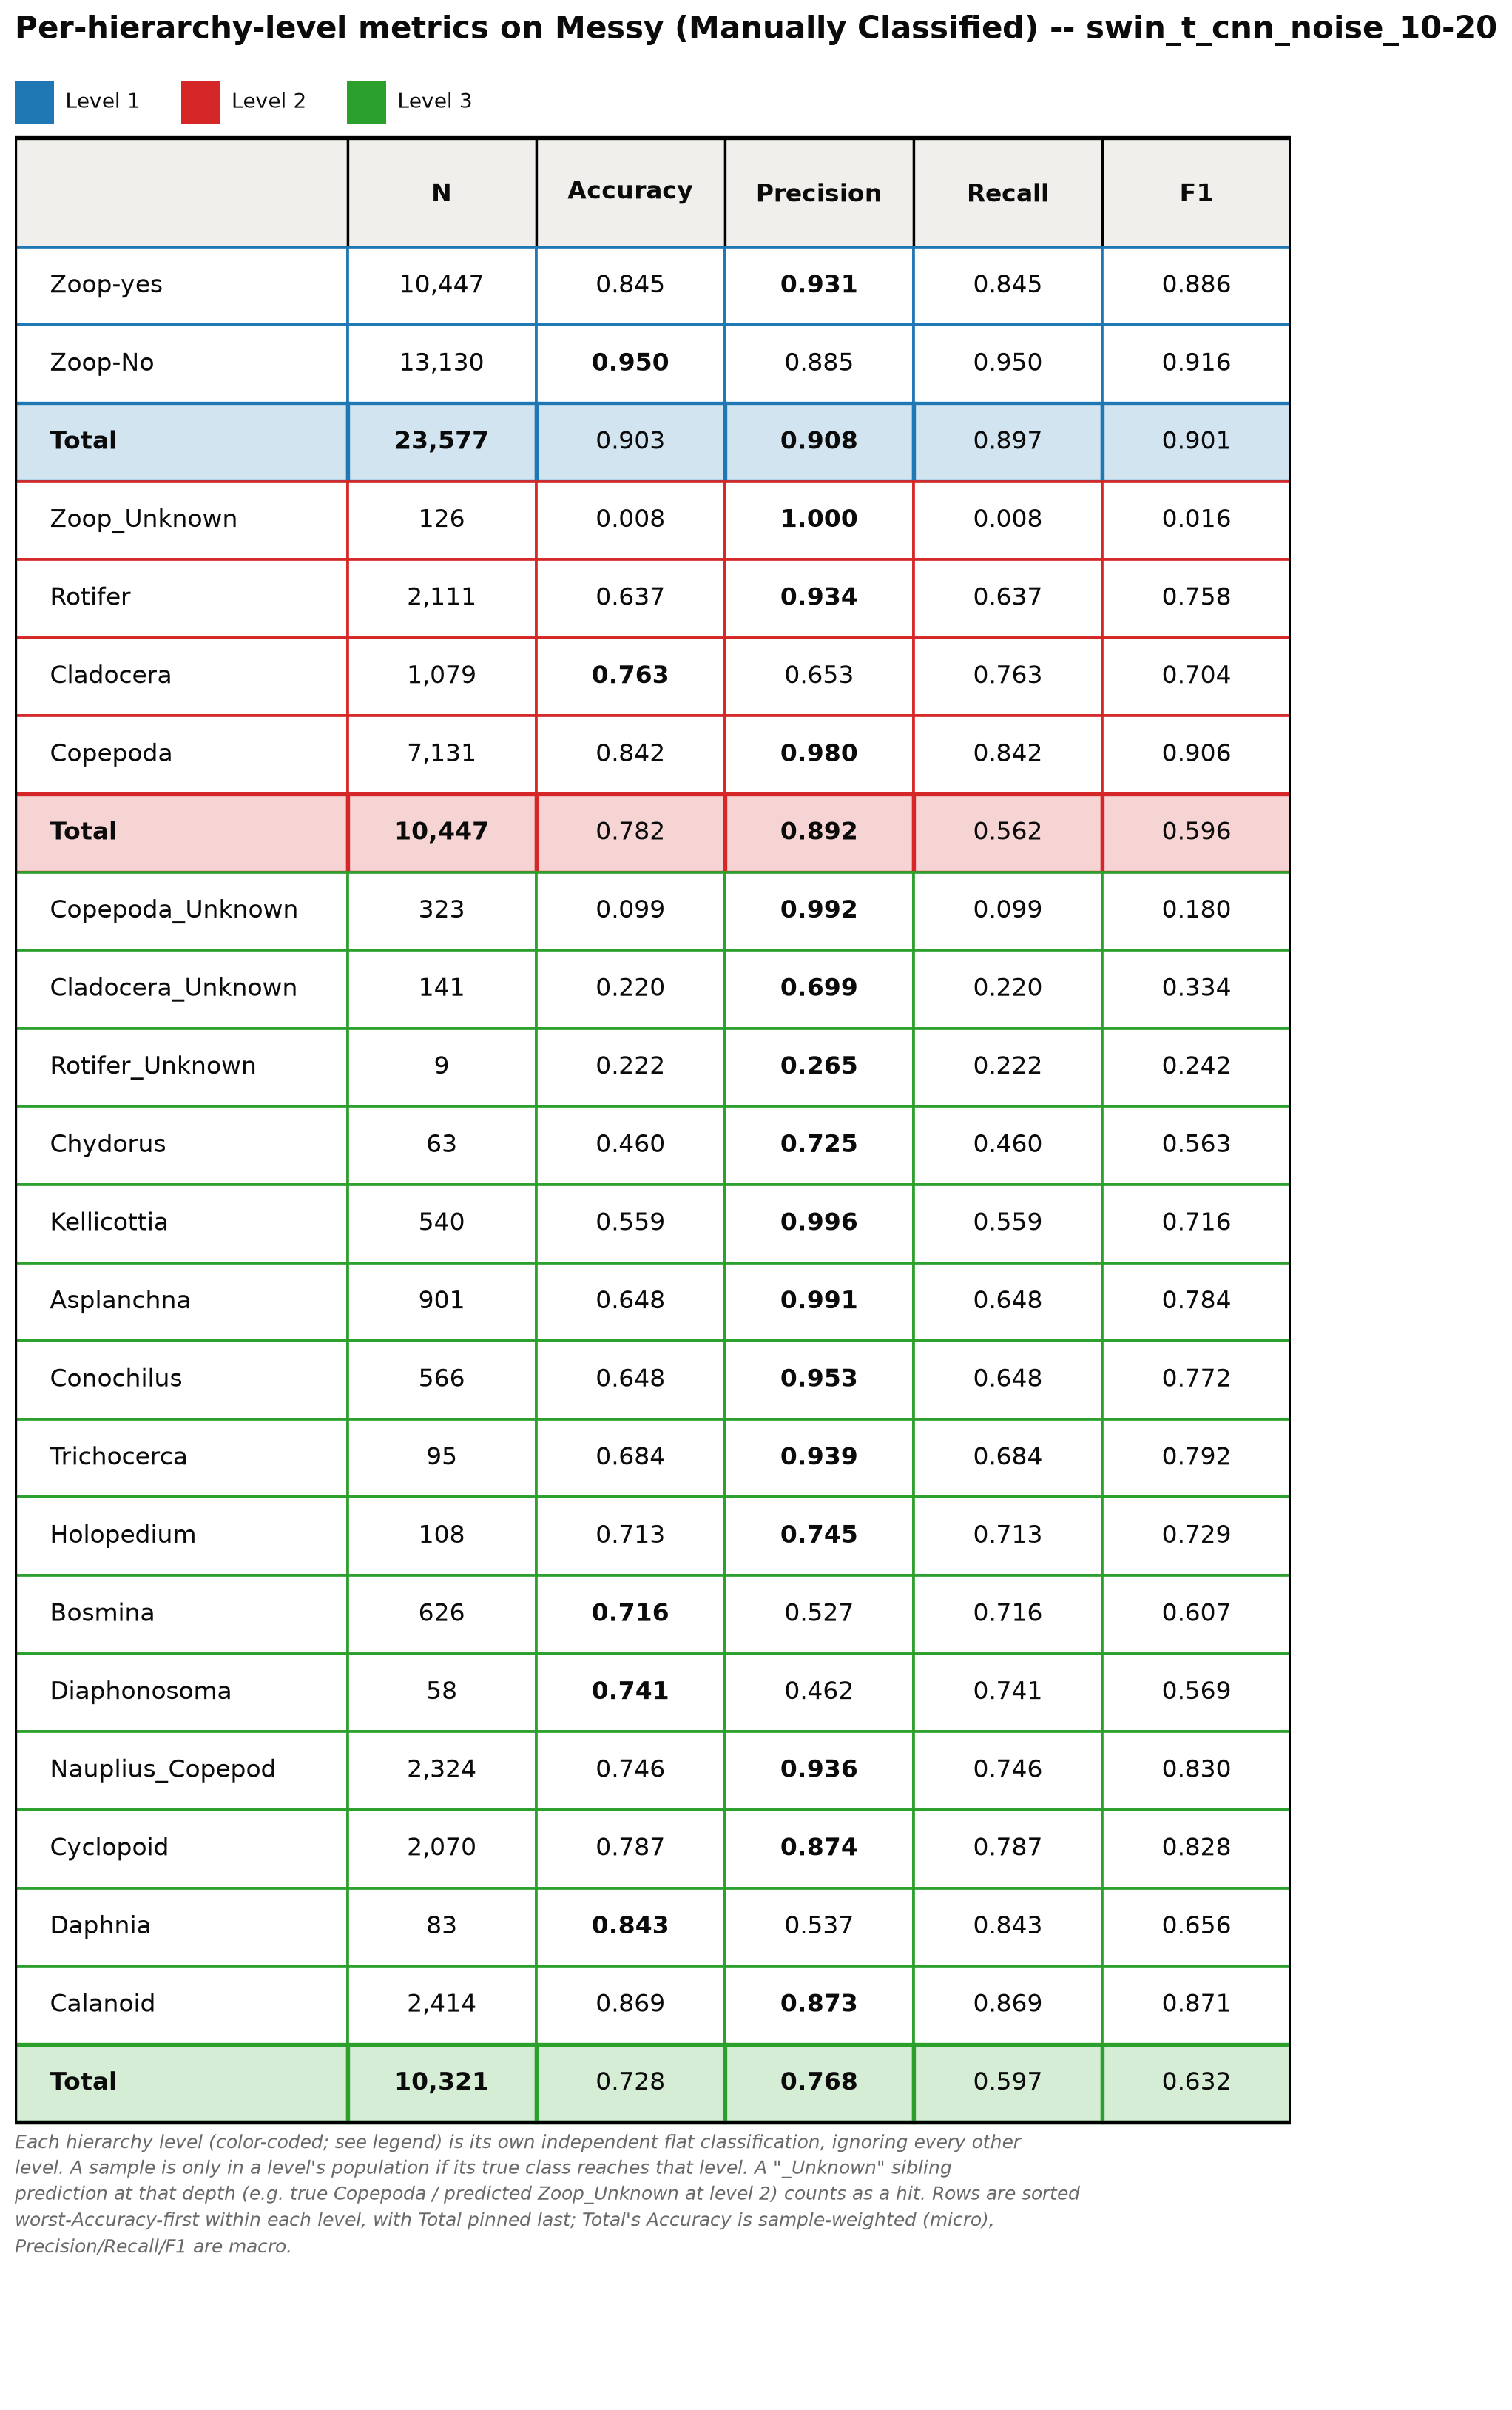

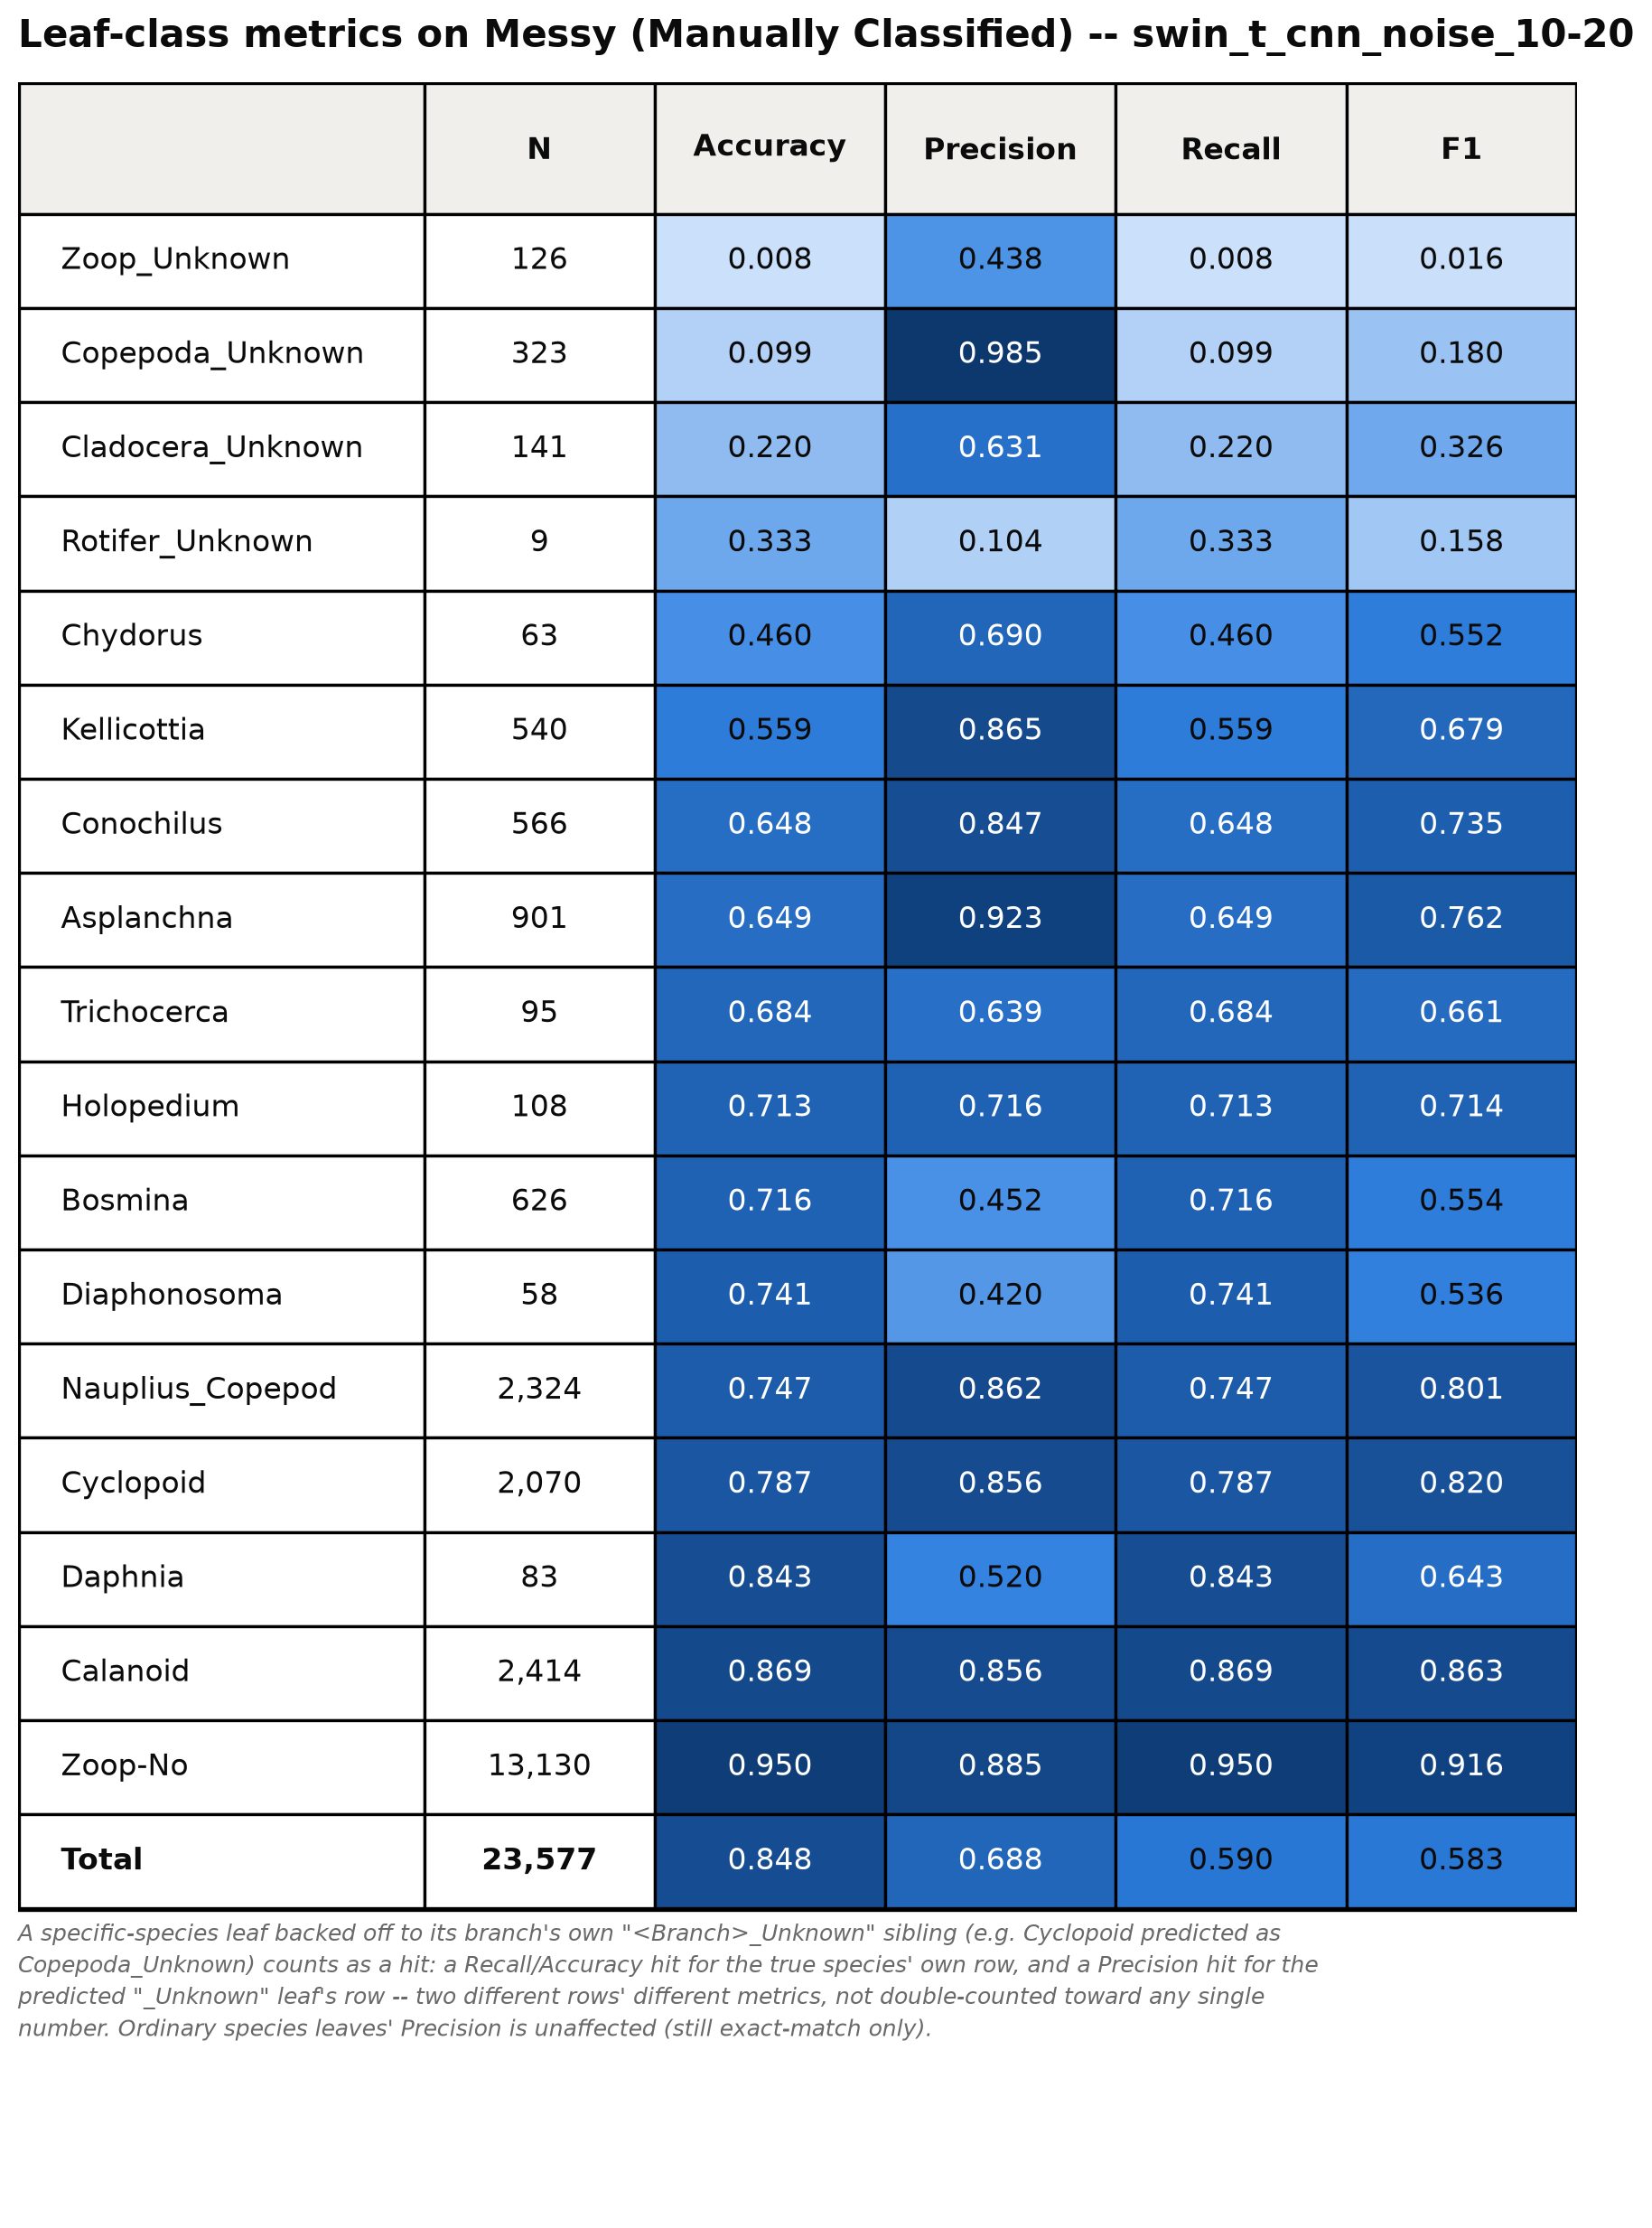

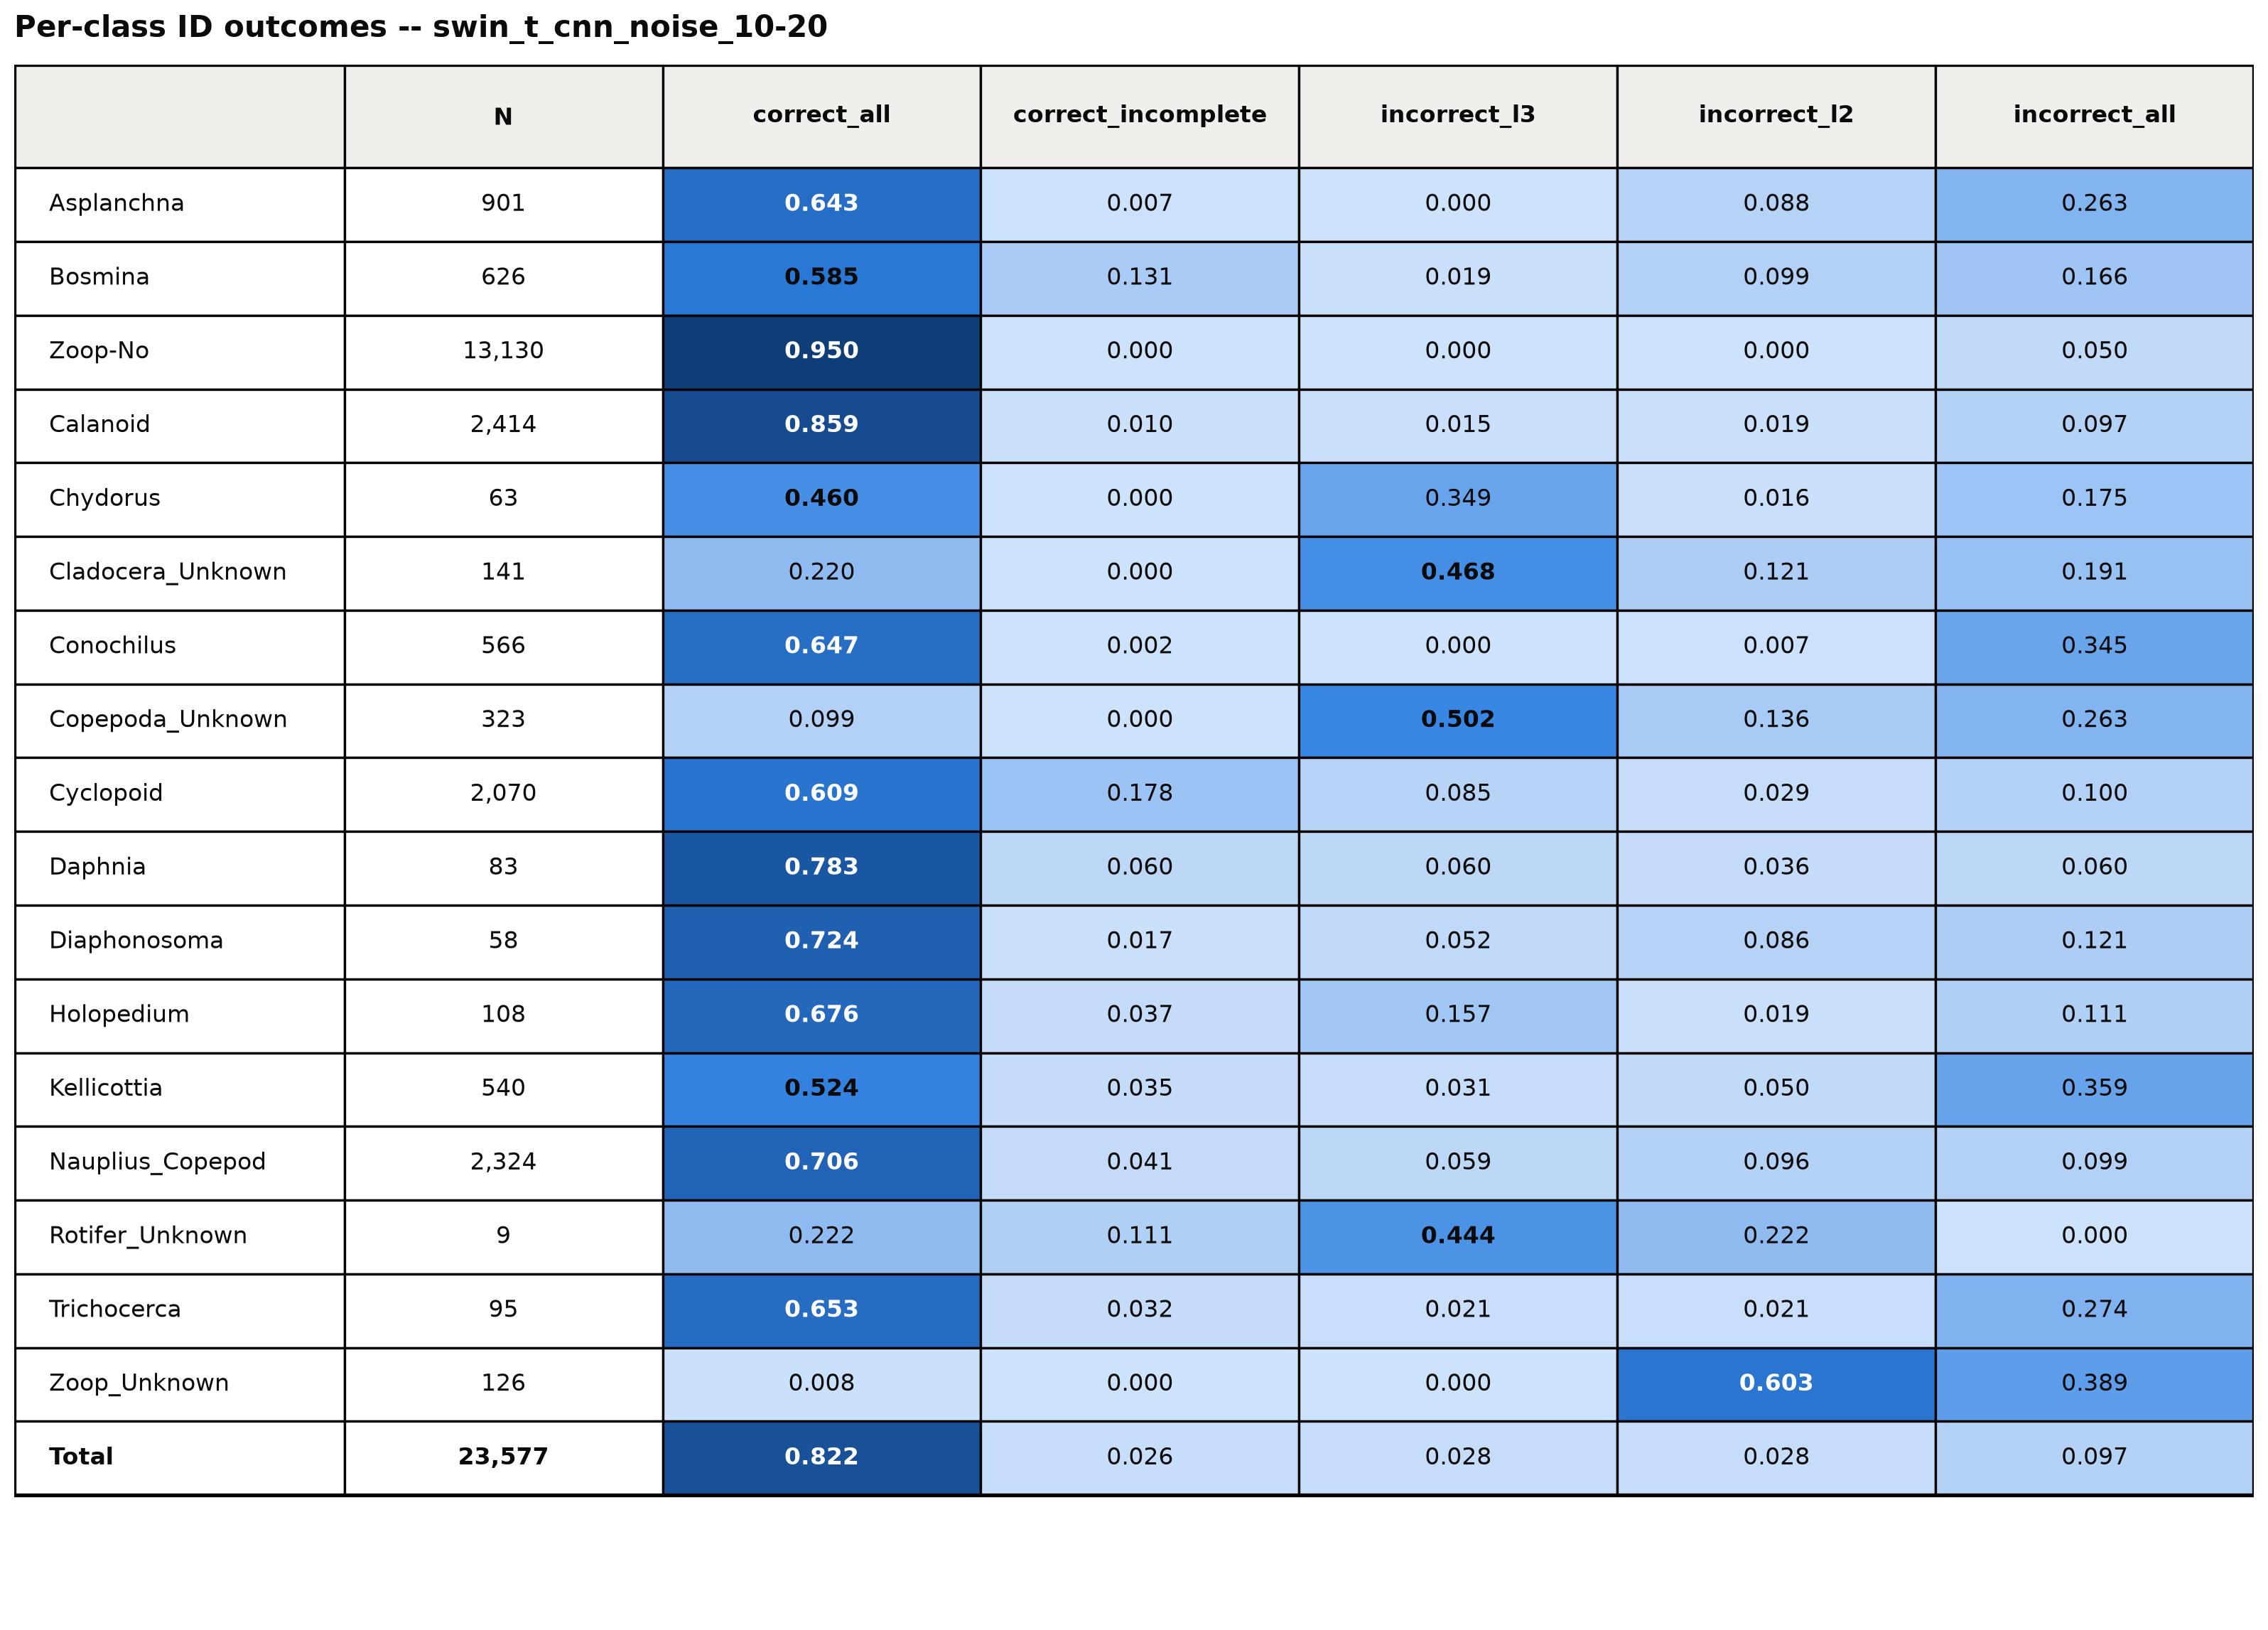

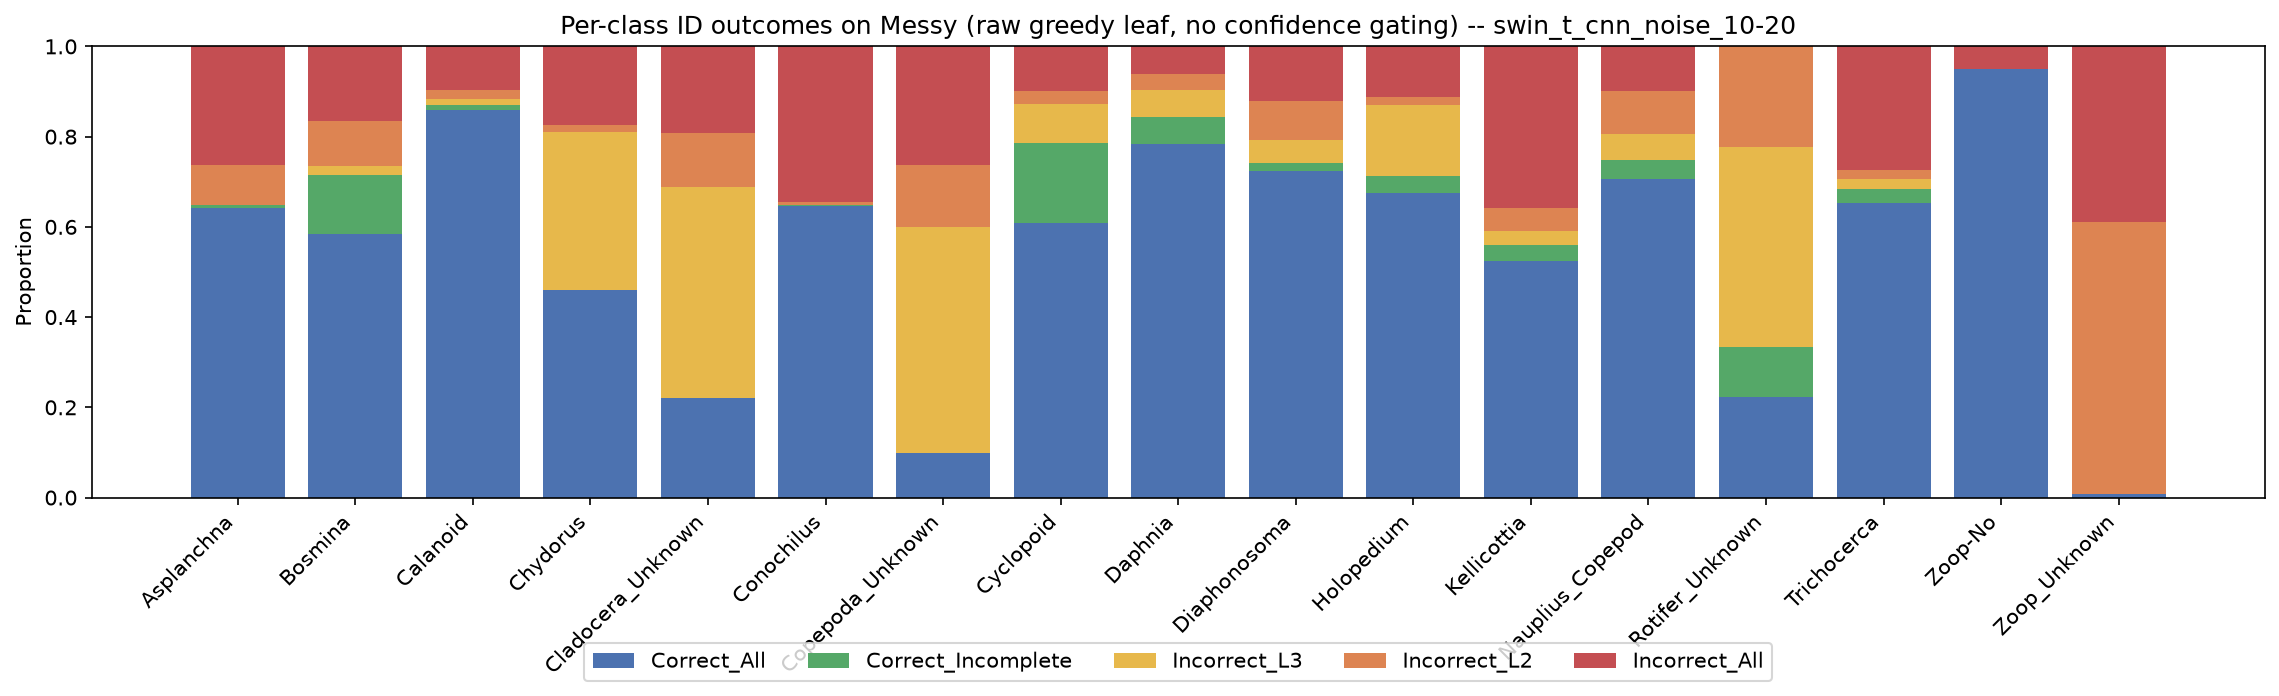

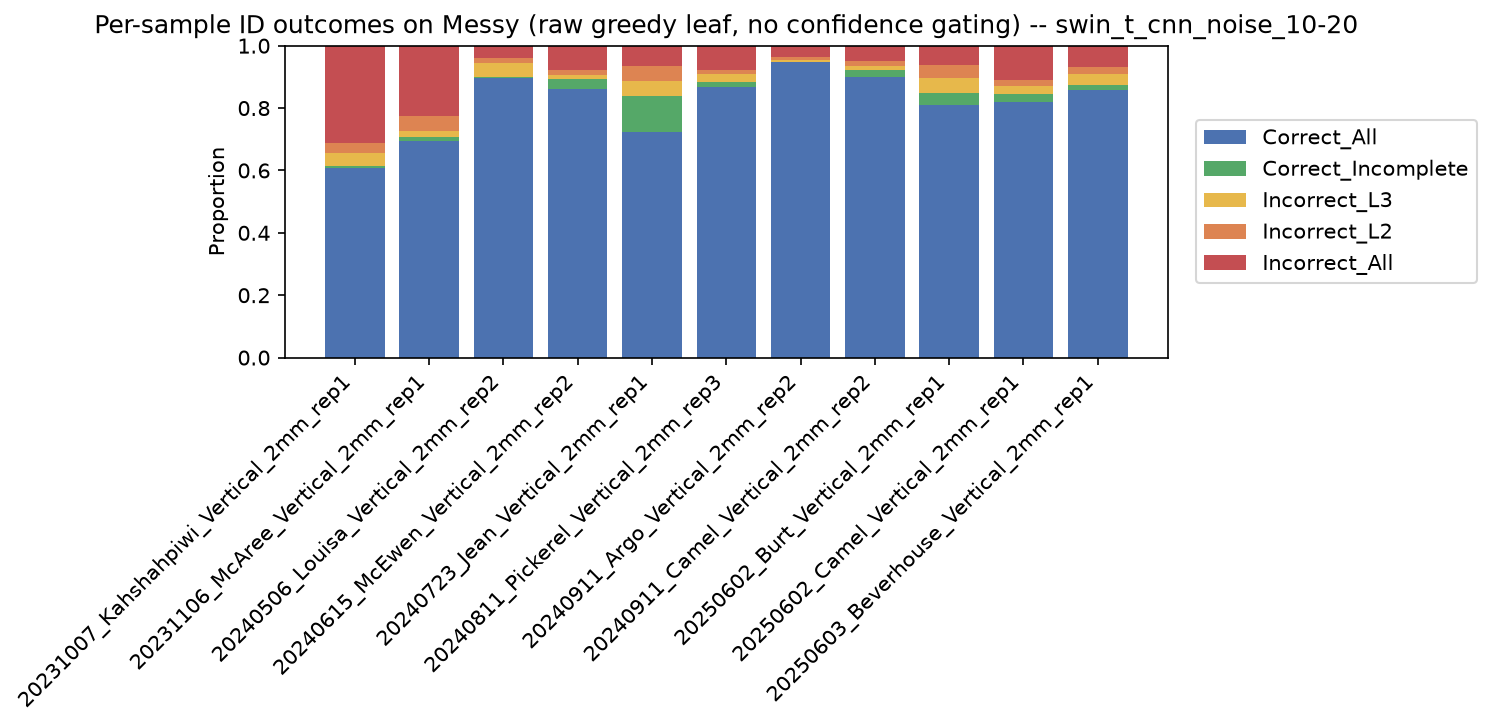

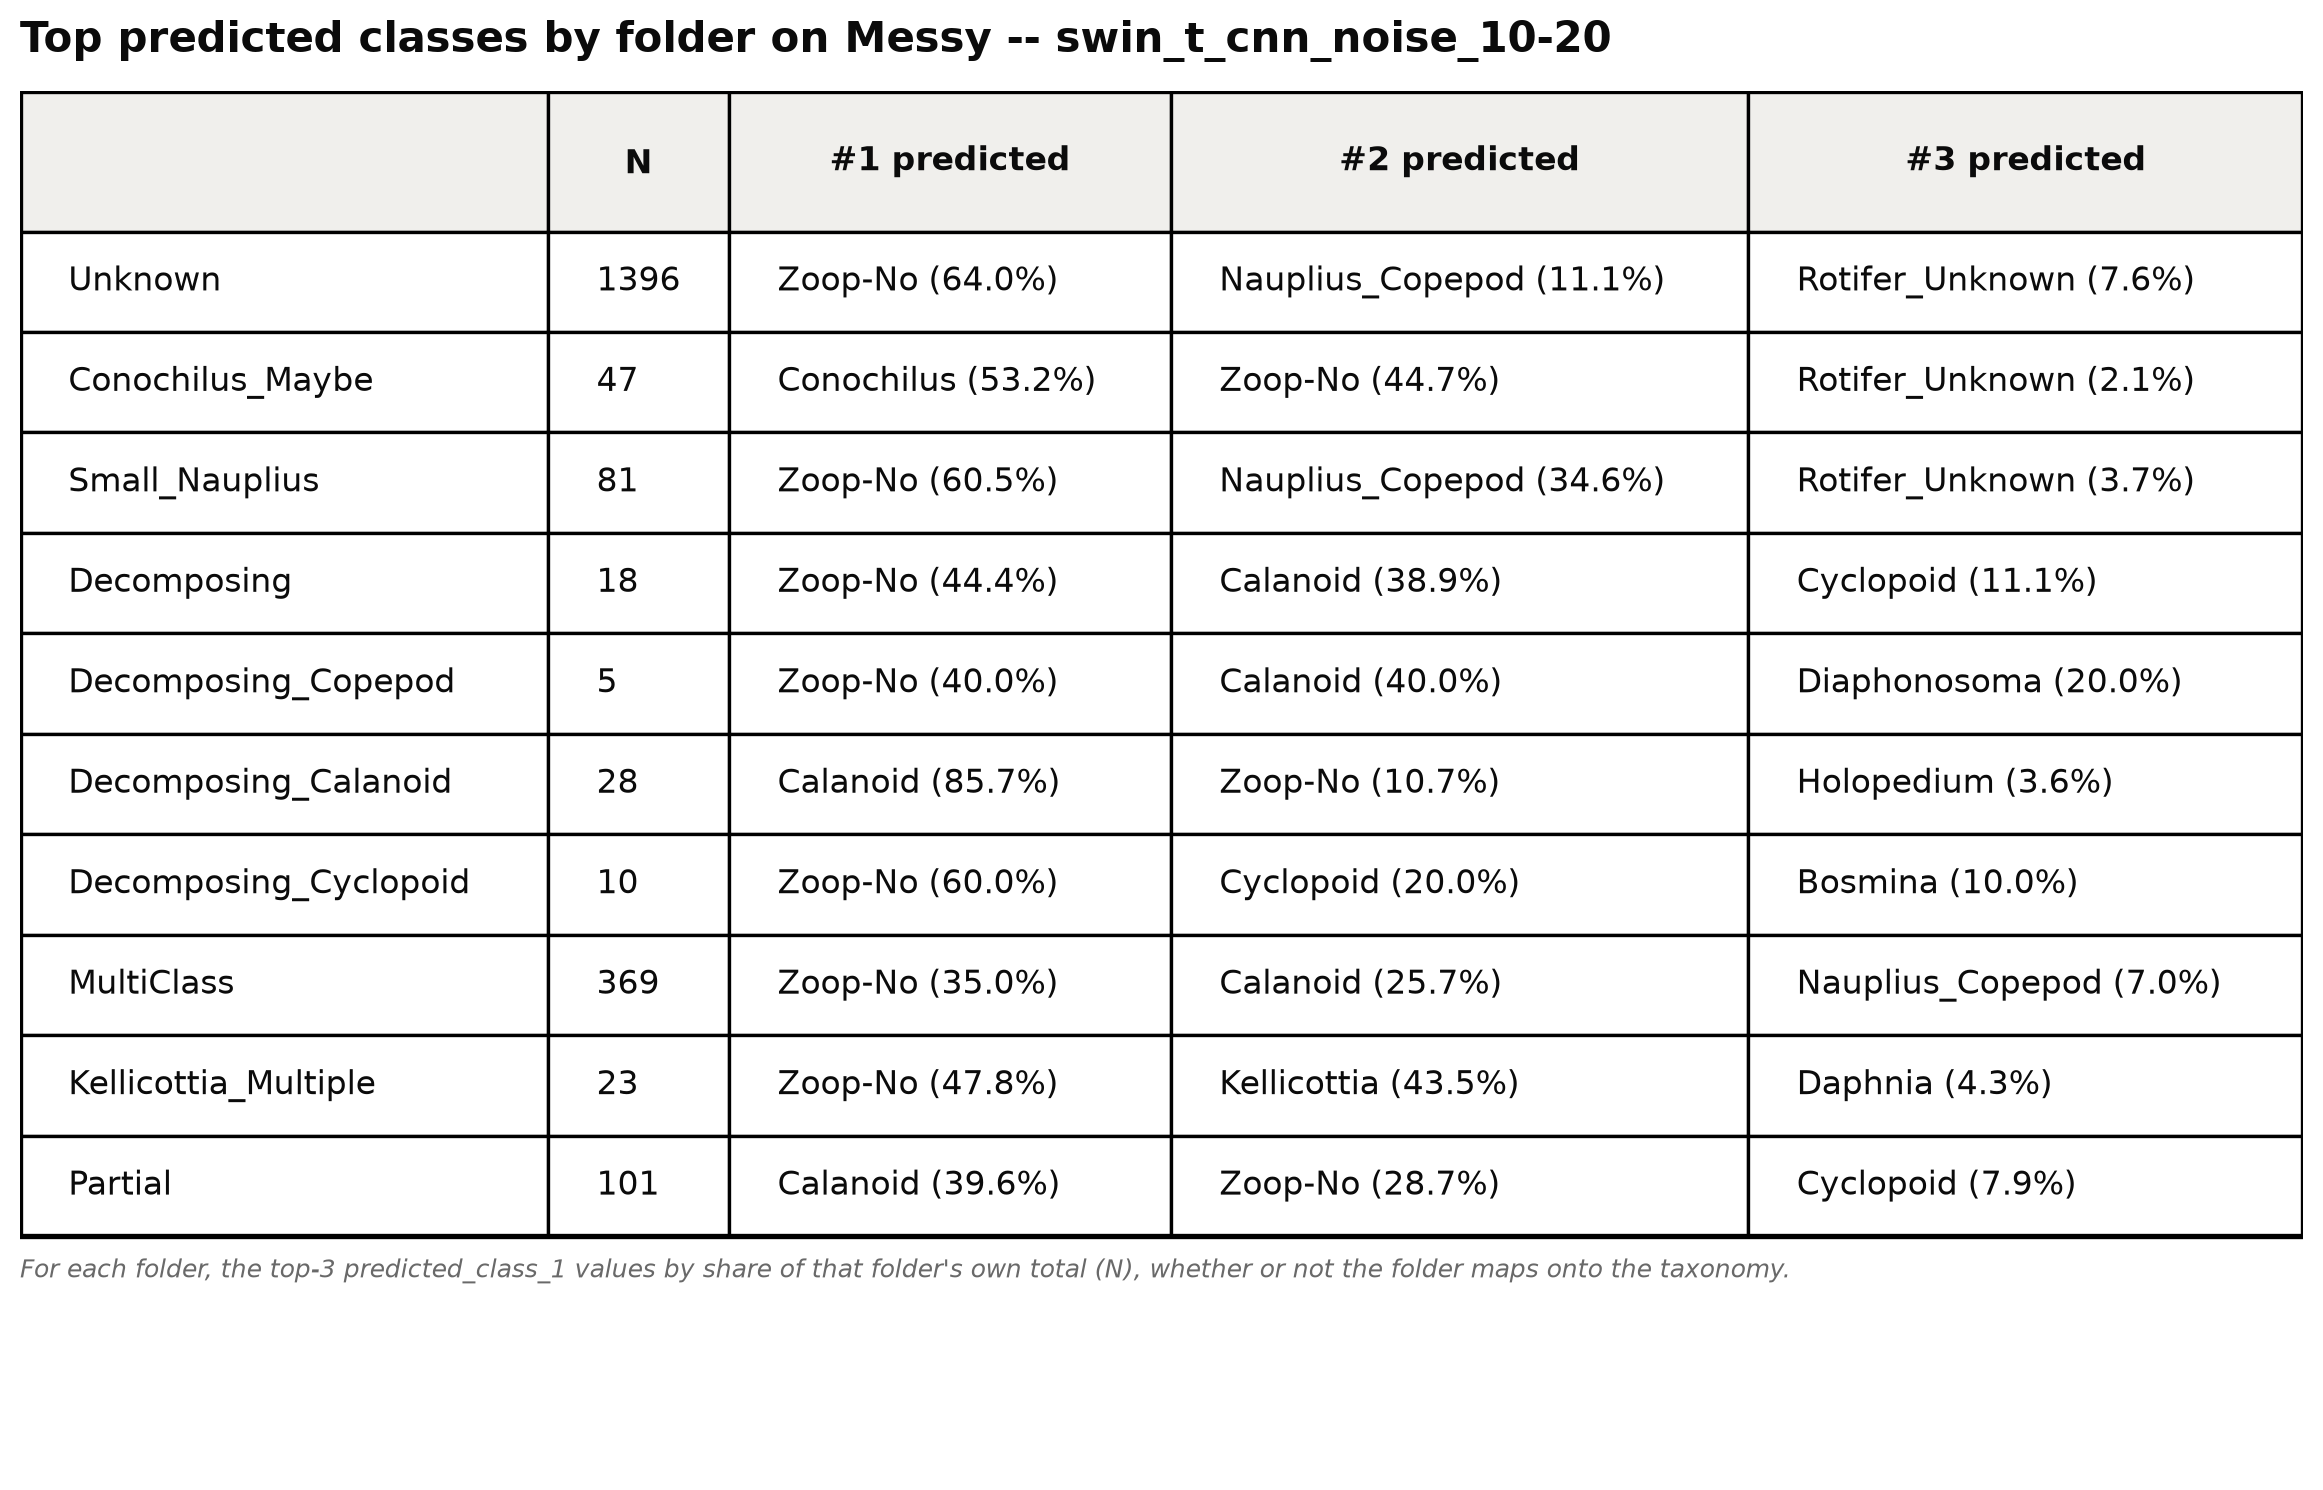

In [10]:
for name in ["hierarchy_level_metrics.png", "leaf_accuracy.png", "id_outcomes_table.png",
             "id_outcomes_stacked_bar.png", "id_outcomes_stacked_bar_by_sample.png",
             "top_predictions_breakdown.png"]:
    display(ShowImage(filename=NOISE_OUT / name, width=750))

**Expected results.** These match the original evaluation exactly:
- 23,577 of the 25,564 particles are graded
- level accuracy is 0.903 / 0.782 / 0.728 (`hierarchy_level_metrics.png`)
- leaf accuracy is 0.848 (`leaf_accuracy.png`)
- 82.2% of graded particles are `correct_all`

The ID outcome shares:

In [11]:
OUTCOMES = ["correct_all", "correct_incomplete", "incorrect_l3", "incorrect_l2", "incorrect_all"]

def outcome_shares(df):
    graded = df[df["in_taxonomy"]]
    return graded[OUTCOMES].astype(bool).mean()

print(f"graded {int(released['in_taxonomy'].sum())} of {len(released)}")
outcome_shares(released).round(4)

graded 23577 of 25564


correct_all           0.8219
correct_incomplete    0.0259
incorrect_l3          0.0279
incorrect_l2          0.0277
incorrect_all         0.0966
dtype: float64

`predictions.csv` has one row per image:
- `predicted_class_1`, and the runner-up `predicted_class_2`
- the prediction and the model's confidence at each level of the tree
- the ID outcome (`correct_all` … `incorrect_all`)
- the FlowCam measurements (`csv_*`)

In [12]:
released[["image_file", "actual_class", "predicted_class_1", "predicted_class_2",
          "confidence_level_1", "confidence_level_2", "confidence_level_3",
          "predicted_level_1", "predicted_level_2", "predicted_level_3", "correct_all"]].head()

,image_file,actual_class,predicted_class_1,predicted_class_2,confidence_level_1,confidence_level_2,confidence_level_3,predicted_level_1,predicted_level_2,predicted_level_3,correct_all
0,20231007_Kahshahpiwi_Vertical_2mm_rep1_000001_...,Asplanchna,Bosmina,Asplanchna,0.930914,0.72729,0.999936,Zoop-yes,Cladocera,Bosmina,False
1,20231007_Kahshahpiwi_Vertical_2mm_rep1_000003_...,Asplanchna,Zoop-No,Asplanchna,0.999917,NaN,NaN,Zoop-No,NaN,NaN,False
2,20231007_Kahshahpiwi_Vertical_2mm_rep1_000003_...,Asplanchna,Zoop-No,Asplanchna,0.999449,NaN,NaN,Zoop-No,NaN,NaN,False
3,20231007_Kahshahpiwi_Vertical_2mm_rep1_000003_...,Asplanchna,Zoop-No,Asplanchna,0.999771,NaN,NaN,Zoop-No,NaN,NaN,False
4,20231007_Kahshahpiwi_Vertical_2mm_rep1_000004_...,Asplanchna,Zoop-No,Bosmina,1.000000,NaN,NaN,Zoop-No,NaN,NaN,False


In [13]:
# Where do the zooplankton end up? (rows: manual class as graded, columns: prediction, row %)
graded_as = released["actual_class"].map(mapping)
zoop = released[graded_as.notna() & (graded_as != "Zoop-No")]
pd.crosstab(graded_as[zoop.index], zoop["predicted_class_1"], normalize="index").round(2)

predicted_class_1,Asplanchna,Bosmina,Calanoid,Chydorus,Cladocera_Unknown,Conochilus,Copepoda_Unknown,Cyclopoid,Daphnia,Diaphonosoma,Holopedium,Kellicottia,Nauplius_Copepod,Rotifer_Unknown,Trichocerca,Zoop-No,Zoop_Unknown
actual_class,,,,,,,,,,,,,,,,,
Asplanchna,0.64,0.08,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.26,0.00
Bosmina,0.00,0.58,0.01,0.01,0.13,0.00,0.01,0.01,0.01,0.00,0.00,0.00,0.04,0.04,0.00,0.17,0.00
Calanoid,0.00,0.00,0.86,0.00,0.00,0.00,0.01,0.00,0.01,0.00,0.00,0.00,0.01,0.00,0.00,0.10,0.00
Chydorus,0.00,0.35,0.00,0.46,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.00,0.17,0.00
Cladocera_Unknown,0.00,0.23,0.06,0.05,0.22,0.00,0.00,0.02,0.02,0.11,0.06,0.00,0.01,0.04,0.00,0.19,0.00
Conochilus,0.00,0.00,0.00,0.00,0.00,0.65,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,0.00
Copepoda_Unknown,0.00,0.03,0.23,0.00,0.04,0.00,0.10,0.23,0.01,0.03,0.00,0.00,0.04,0.02,0.00,0.26,0.00
Cyclopoid,0.00,0.00,0.07,0.00,0.00,0.00,0.18,0.61,0.01,0.01,0.00,0.00,0.01,0.00,0.00,0.10,0.00
Daphnia,0.00,0.02,0.04,0.00,0.06,0.00,0.00,0.00,0.78,0.00,0.04,0.00,0.00,0.00,0.00,0.06,0.00


In [14]:
# Low-confidence species calls are good candidates for manual review
released[released["confidence_level_3"] < 0.6].sort_values("confidence_level_3")[
    ["image_file", "actual_class", "predicted_class_1", "predicted_class_2", "confidence_level_3"]].head(10)

,image_file,actual_class,predicted_class_1,predicted_class_2,confidence_level_3
5780,20240911_Camel_Vertical_2mm_rep2_000007_73.tif,Cyclopoid,Cyclopoid,Copepoda_Unknown,0.315800
21506,20240506_Louisa_Vertical_2mm_rep2_000002_11.tif,Nauplius_Copepod,Copepoda_Unknown,Cyclopoid,0.316497
25093,20250602_Burt_Vertical_2mm_rep1_000008_53.tif,Unknown,Copepoda_Unknown,Cyclopoid,0.318533
23348,20250602_Burt_Vertical_2mm_rep1_000026_420.tif,Nauplius_Copepod,Copepoda_Unknown,Cyclopoid,0.324333
22876,20250602_Burt_Vertical_2mm_rep1_000018_1414.tif,Nauplius_Copepod,Nauplius_Copepod,Cyclopoid,0.340315
5360,20240506_Louisa_Vertical_2mm_rep2_000002_2.tif,Cyclopoid,Copepoda_Unknown,Calanoid,0.352821
21526,20240506_Louisa_Vertical_2mm_rep2_000004_29.tif,Nauplius_Copepod,Copepoda_Unknown,Nauplius_Copepod,0.354479
20914,20250602_Camel_Vertical_2mm_rep1_000009_218.tif,Kellicottia_Smalls,Kellicottia,Trichocerca,0.354686
3496,20250602_Burt_Vertical_2mm_rep1_000024_740.tif,Calanoid,Diaphonosoma,Daphnia,0.359158
23454,20250602_Camel_Vertical_2mm_rep1_000003_28.tif,Nauplius_Copepod,Cyclopoid,Calanoid,0.364134


## B. Your trained model on the same test set

Pass the run folder from `train.ipynb` as `weights`; its `model_config.json` tells hierroute how to
rebuild the model. A full run of `train.ipynb` should land close to the released model, but not exactly
on it (see the note at the top of `train.ipynb`).

Model: swin_t_cnn_noise_example (swin_t + cnn experts, hierarchy mnr_17leaf) | device: cuda
Images: 25564
  20032/25564 images
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_own_model_example/predictions.csv
Graded 23577 of 25564 images against the taxonomy
Folders not in the taxonomy (kept in predictions.csv, not graded): Unknown (1396), MultiClass (369), Partial (101), Conochilus_Maybe (47), Decomposing_Calanoid (28), Kellicottia_Multiple (23), Decomposing_Cyclopoid (10), Duplicate_Zooplankton (8), Decomposing_Copepod (5)
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_own_model_example/leaf_accuracy.png
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_own_model_example/hierarchy_level_metrics.png
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_own_model_example/id_outcomes_stacked_bar.png
Saved -> /home/tjhinale/repo/Zooplankton_

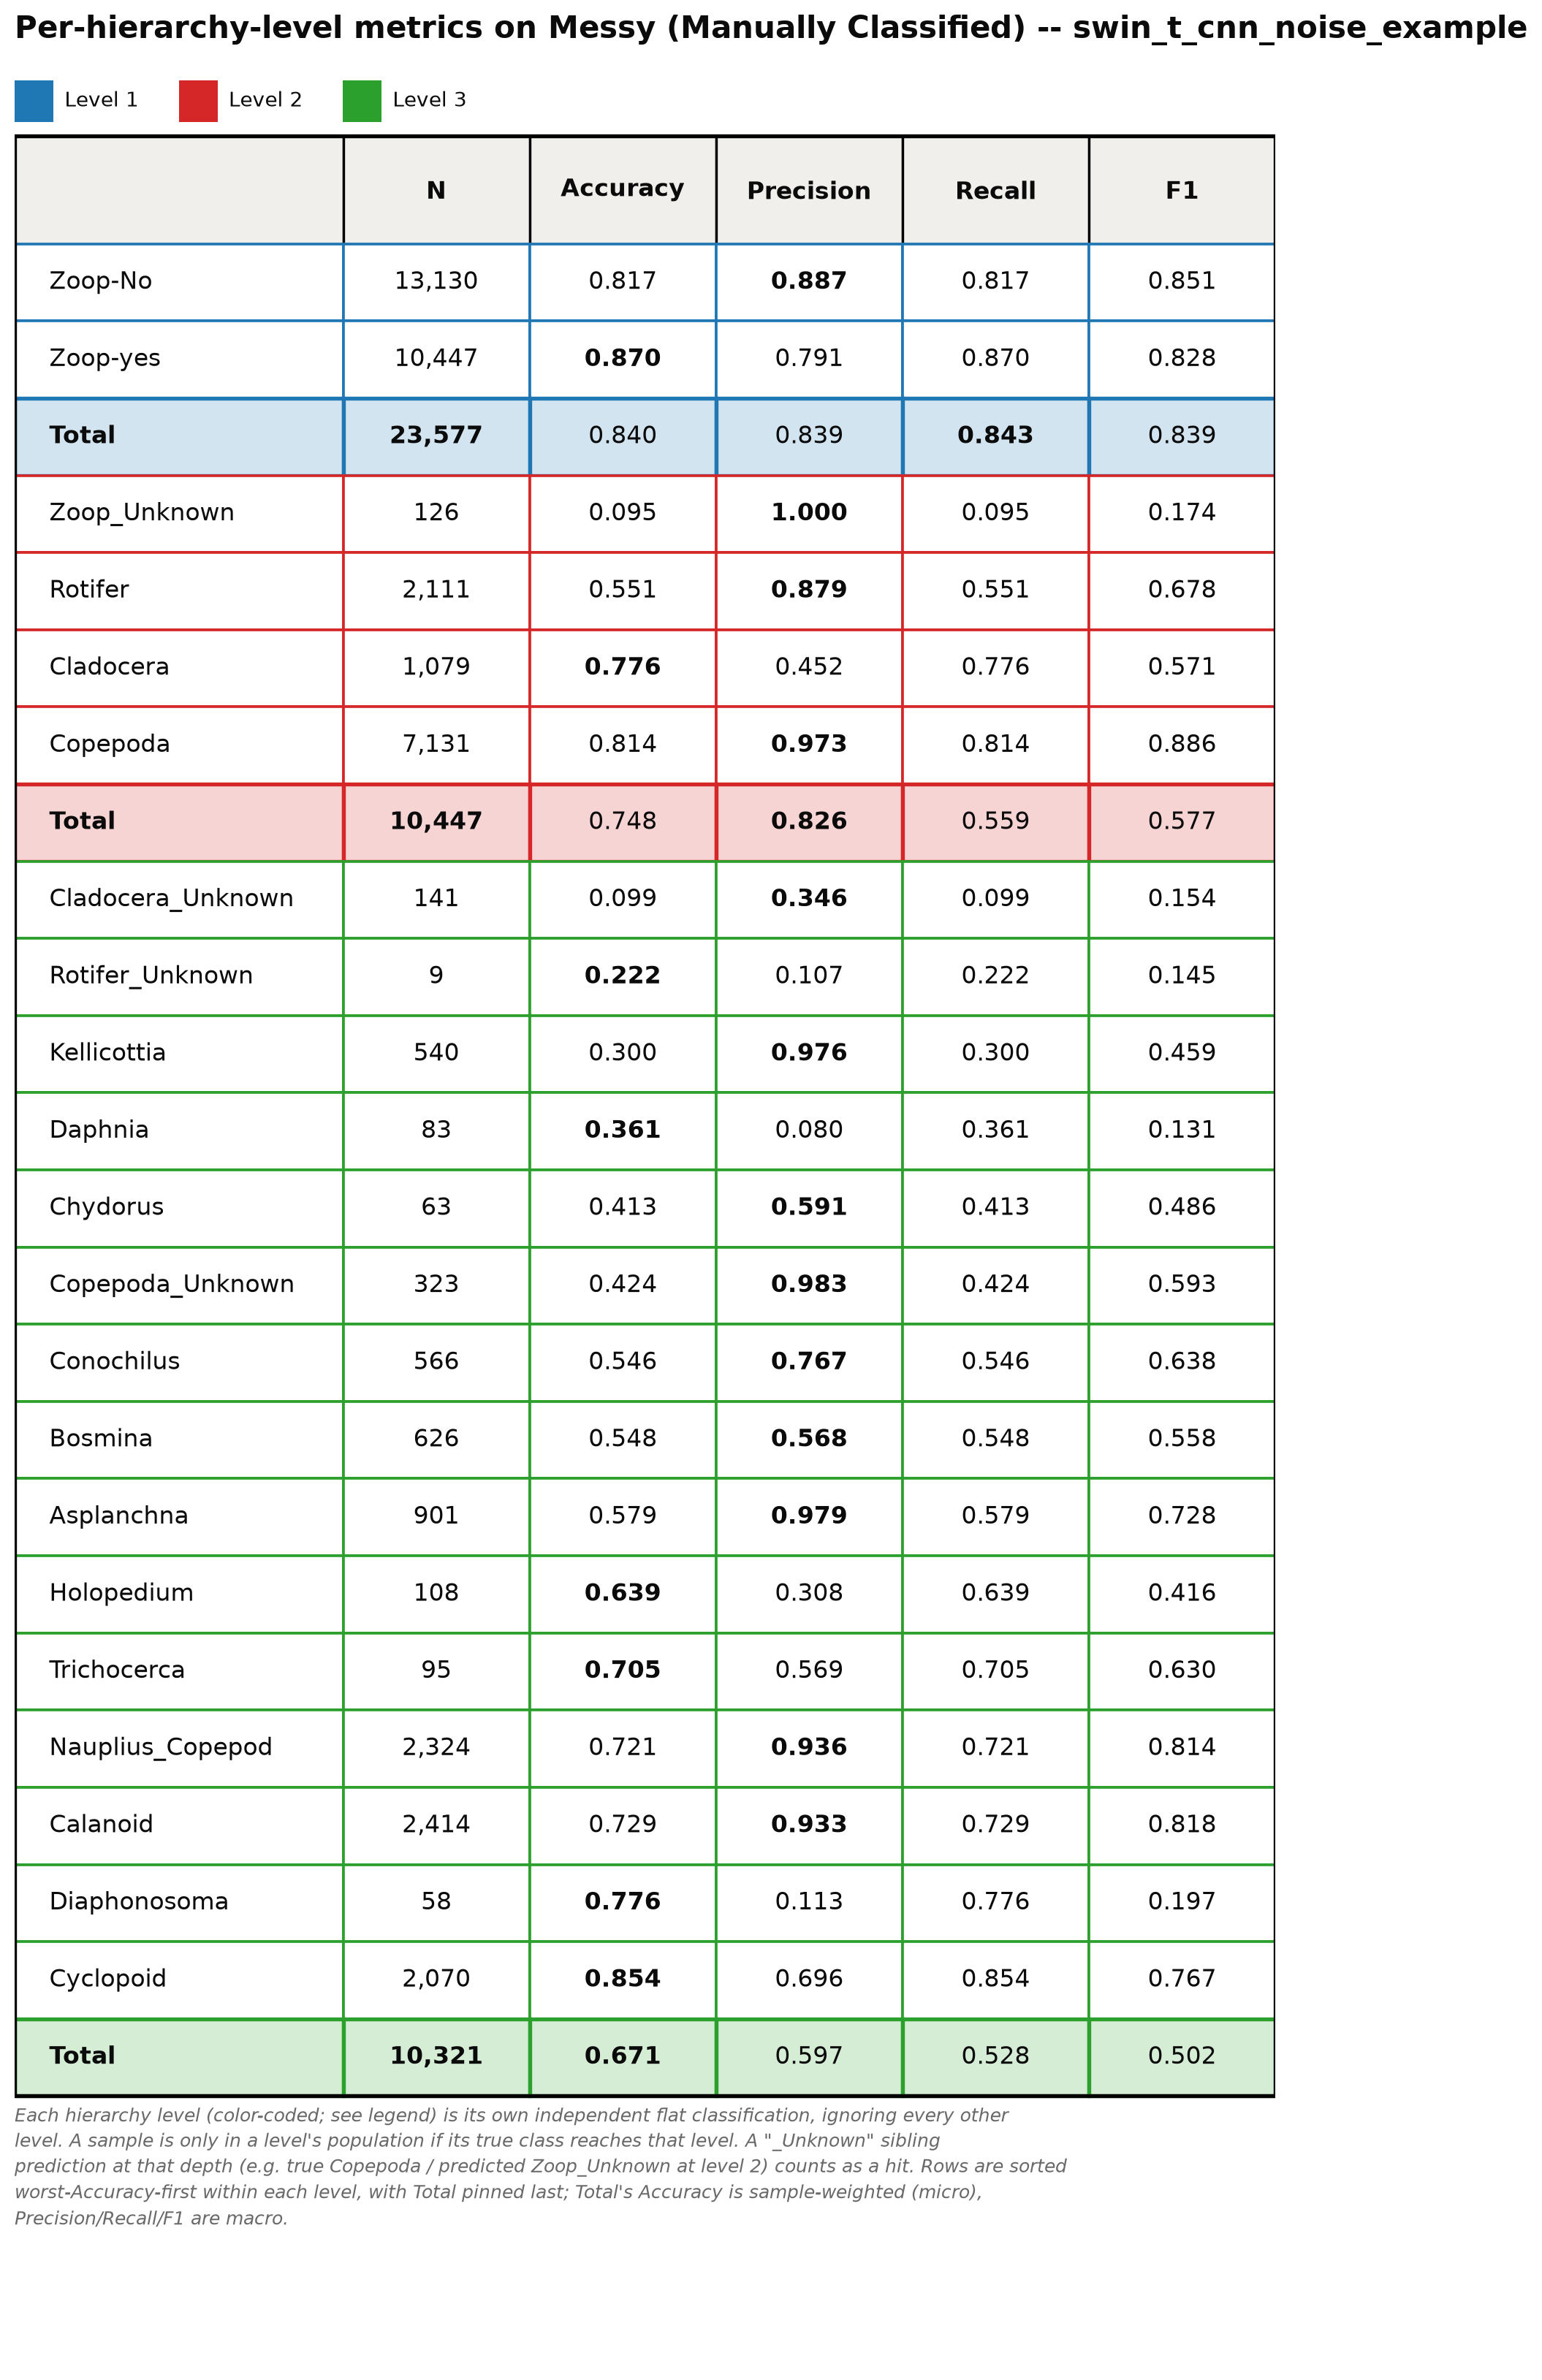

In [15]:
QUETICO_OPTIONS = dict(input=QUETICO, labelled=True, folder_map=QUETICO_FOLDERS,
                       class_rules=ClassRules(rename={"Cladoceran": "Cladocera"}))

if RUN_DIR.exists():
    own = evaluate(EvaluateOptions(out_dir=OWN_OUT, weights=RUN_DIR,
                                   **QUETICO_OPTIONS))
    display(ShowImage(filename=OWN_OUT / "hierarchy_level_metrics.png",
                      width=750))
else:
    own = None
    print(f"No trained model at {RUN_DIR} -- run train.ipynb first.")

In [16]:
# Share of graded particles in each ID outcome, released vs your model
compare = {"released noise model": outcome_shares(released)}
if own is not None:
    compare["your model (train.ipynb)"] = outcome_shares(own)
pd.DataFrame(compare).round(4)

,released noise model,your model (train.ipynb)
correct_all,0.8219,0.6339
correct_incomplete,0.0259,0.1304
incorrect_l3,0.0279,0.0220
incorrect_l2,0.0277,0.0539
incorrect_all,0.0966,0.1598


## C. Classify a raw FlowCam export

New data usually arrives as a raw export (mosaics plus CSVs), not as sorted crops. With
`input_type="flowcam"`, the model reads the mosaics and CSVs directly and crops each particle in memory;
there is no need to run `preprocess.ipynb` first.

Here we use the raw export the Quetico crops came from and leave `labelled` off, as you would for a new
sample. The model finds the same 25,564 particles and gives them the same classes as in section A. The
result is one row per particle with its `run`, so counts per sample are a single `crosstab`.

In [17]:
raw = evaluate(EvaluateOptions(
    input=QUETICO / "Classified_data",      # mosaics, one folder per run
    csv_dir=QUETICO / "CSV_Data",           # the export CSVs
    input_type="flowcam",
    out_dir=RAW_OUT,
))

Model: swin_t_cnn_noise_10-20 (swin_t + cnn experts, hierarchy mnr_17leaf) | device: cuda
25564 particles from 11 CSV(s) across 148 mosaic(s)
  ok: 25564
  mosaics with no CSV rows: 22 (e.g. 20231007_Kahshahpiwi_Vertical_2mm_rep1_000009.tif)
Images: 25564
Saved -> /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_raw_example/predictions.csv
predicted_class_1
Zoop-No              15195
Calanoid              2615
Nauplius_Copepod      2087
Cyclopoid             1520
Bosmina                908
Asplanchna             655
Copepoda_Unknown       546
Conochilus             516
Rotifer_Unknown        413
Kellicottia            360
Cladocera_Unknown      219
Daphnia                137
Diaphonosoma           111
Trichocerca            108
Holopedium             107
Chydorus                43
Zoop_Unknown            24

All outputs saved under /home/tjhinale/repo/Zooplankton_Classification/inference_result/quetico_messy_raw_example


In [18]:
# Particles per predicted class in each run
counts = pd.crosstab(raw["predicted_class_1"], raw["run"])
counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]

run,20231007_Kahshahpiwi_Vertical_2mm_rep1,20231106_McAree_Vertical_2mm_rep1,20240506_Louisa_Vertical_2mm_rep2,20240615_McEwen_Vertical_2mm_rep2,20240723_Jean_Vertical_2mm_rep1,20240811_Pickerel_Vertical_2mm_rep3,20240911_Argo_Vertical_2mm_rep2,20240911_Camel_Vertical_2mm_rep2,20250602_Burt_Vertical_2mm_rep1,20250602_Camel_Vertical_2mm_rep1,20250603_Beverhouse_Vertical_2mm_rep1
predicted_class_1,,,,,,,,,,,
Zoop-No,604,2240,664,629,361,665,879,3956,1704,2310,1183
Calanoid,254,150,238,143,167,60,49,104,995,224,231
Nauplius_Copepod,4,78,56,60,53,59,14,251,1142,163,207
Cyclopoid,19,117,47,41,100,21,7,83,629,257,199
Bosmina,37,254,11,37,33,11,11,176,154,122,62
Asplanchna,3,328,0,3,12,42,2,38,1,218,8
Copepoda_Unknown,1,14,7,22,95,15,1,83,190,83,35
Conochilus,14,90,2,31,11,12,2,20,19,267,48
Rotifer_Unknown,1,34,5,19,14,29,14,117,69,79,32


In [19]:
# Same per-class totals as the labelled crops in section A
pd.DataFrame({"raw export": raw["predicted_class_1"].value_counts(),
              "crops (section A)": released["predicted_class_1"].value_counts()})

,raw export,crops (section A)
predicted_class_1,,
Zoop-No,15195,15195
Calanoid,2615,2615
Nauplius_Copepod,2087,2087
Cyclopoid,1520,1520
Bosmina,908,908
Asplanchna,655,655
Copepoda_Unknown,546,546
Conochilus,516,516
Rotifer_Unknown,413,413


In [20]:
# Optional: only trust species-level calls above a confidence threshold; otherwise report the group
confident = raw["confidence_level_3"].fillna(1) >= 0.9
raw["reported_class"] = raw["predicted_class_1"].where(
    confident, raw["predicted_level_2"].fillna(raw["predicted_level_1"]))
raw["reported_class"].value_counts()

reported_class
Zoop-No              15195
Calanoid              2394
Nauplius_Copepod      1980
Cyclopoid             1094
Copepoda               947
Bosmina                802
Asplanchna             655
Conochilus             512
Rotifer_Unknown        399
Copepoda_Unknown       353
Kellicottia            344
Cladocera              240
Cladocera_Unknown      153
Daphnia                105
Trichocerca            103
Diaphonosoma            96
Holopedium              95
Rotifer                 39
Chydorus                34
Zoop_Unknown            24
Name: count, dtype: int64

## D. From Python, image by image

`load_model` returns the network and its config. `Predictor` gives the greedy path through the
taxonomy, the confidence at each step and a runner-up. This is useful for building your own tools on
top of hierroute.

In [21]:
import torch
from PIL import Image
from hierroute import load_model
from hierroute.inference import Predictor, eval_transform

device = "cuda" if torch.cuda.is_available() else "cpu"
model, config = load_model("noise", device=device)
predictor = Predictor(model, device)
transform = eval_transform(config.resolution)

files = [sorted((QUETICO / c).glob("*.tif"))[0] for c in ["Calanoid", "Bosmina", "Kellicottia", "Detritus"]]
batch = torch.stack([transform(Image.open(f).convert("L")).repeat(3, 1, 1) for f in files])

for f, pred in zip(files, predictor(batch)):
    path = " > ".join(predictor.id_to_name[n] for n in pred.path[1:])
    confs = ", ".join(f"{c:.3f}" for c in pred.confidences)
    print(f"{f.parent.name:12s} -> {path:40s} confidences {confs} | runner-up {pred.predicted_2}")

Calanoid     -> Zoop-No                                  confidences 0.582 | runner-up Calanoid
Bosmina      -> Zoop-No                                  confidences 0.799 | runner-up Bosmina
Kellicottia  -> Zoop-No                                  confidences 0.888 | runner-up Kellicottia
Detritus     -> Zoop-No                                  confidences 1.000 | runner-up Trichocerca


## The same from the terminal

Run from the repository root. The extra folder rules and the class rename go in two small YAML files:

```bash
printf 'Duplicate: Zoop-No\nKellicottia_Smalls: Kellicottia\n' > quetico_folders.yaml
printf 'Cladoceran: Cladocera\n' > quetico_classes.yaml

# A: labelled crops, released model
hierroute evaluate /data/Hier-Zooplankton/quetico/Messy --labelled --model noise \
    --folder-map quetico_folders.yaml --class-map quetico_classes.yaml \
    --zoop-only --by-sample \
    --breakdown Unknown Conochilus_Maybe Small_Nauplius Decomposing Decomposing_Copepod \
                Decomposing_Calanoid Decomposing_Cyclopoid MultiClass Kellicottia_Multiple Partial \
    --out inference_result/quetico_messy_noise_example

# B: your own model
hierroute evaluate /data/Hier-Zooplankton/quetico/Messy --labelled \
    --weights training_result/swin_t_cnn_noise_example \
    --folder-map quetico_folders.yaml --class-map quetico_classes.yaml --out inference_result/quetico_messy_own_model_example

# C: raw export
hierroute evaluate /data/Hier-Zooplankton/quetico/Messy/Classified_data --input-type flowcam \
    --csv-dir /data/Hier-Zooplankton/quetico/Messy/CSV_Data --out inference_result/quetico_messy_raw_example
```

Other optional outputs (confidence thresholds, capped tables, …) are listed under
`hierroute evaluate -h` and in the README.